#**TRAINING**

##**Data Preprocessing**

In [26]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/CHALLENGE1ANN/CONSEGNE"
%cd $current_dir

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).
/gdrive/My Drive/CHALLENGE1ANN/CONSEGNE


In [27]:
# Set seed for reproducibility
SEED = 50

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
PyTorch version: 2.8.0+cu126
Device: cuda


In [28]:
X_train = pd.read_csv('pirate_pain_train.csv')
y_train = pd.read_csv('pirate_pain_train_labels.csv')
X_test = pd.read_csv('pirate_pain_test.csv')

In [29]:
# since the feature joint_30 is the same value for every sample (0.5) we elimnate it
X_train = X_train.drop('joint_30', axis=1)
X_test = X_test.drop('joint_30', axis=1)

In [30]:
#Change the datatype of joint columns to float32
# Loop for the joint columns
for i in range(30):
    col_name = f'joint_{i:02d}' # Formatting the column name (es. 'joint_00', 'joint_01')
    if col_name in X_train.columns:
        X_train[col_name] = X_train[col_name].astype(np.float32)
        X_test[col_name] = X_test[col_name].astype(np.float32)

print("Verifying data types after conversion using for loop:")
X_train.info()

#the dataset doesn't seem to have any missing values

Verifying data types after conversion using for loop:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 39 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float32
 10  joint_01       105760 non-null  float32
 11  joint_02       105760 non-null  float32
 12  joint_03       105760 non-null  float32
 13  joint_04       105760 non-null  float32
 14  joint_05       105760 non-null  float32
 15  joint_06       105760 non-null  float32
 16  joint_07       10576

In [31]:
columns_to_analyze = ['n_legs', 'n_hands', 'n_eyes']

for col in columns_to_analyze:
    print(f"\nUnique values and counts for column: {col}")
    print(X_train[col].value_counts())


Unique values and counts for column: n_legs
n_legs
two            104800
one+peg_leg       960
Name: count, dtype: int64

Unique values and counts for column: n_hands
n_hands
two              104800
one+hook_hand       960
Name: count, dtype: int64

Unique values and counts for column: n_eyes
n_eyes
two              104800
one+eye_patch       960
Name: count, dtype: int64


In [32]:
# Define a mapping of n_legs values to integer labels
label_mapping_legs = {
    'two': 0,
    'one+peg_leg': 1,
}
# Map n_legs attributes to integers in the training set
X_train['n_legs'] = X_train['n_legs'].map(label_mapping_legs)
X_test['n_legs'] = X_test['n_legs'].map(label_mapping_legs)

# Define a mapping of n_hands values to integer labels
label_mapping_hands = {
    'two': 0,
    'one+hook_hand': 1,
}
# Map n_hands attributes to integers in the training set
X_train['n_hands'] = X_train['n_hands'].map(label_mapping_hands)
X_test['n_hands'] = X_test['n_hands'].map(label_mapping_hands)

# Define a mapping of n_eyes values to integer labels
label_mapping_eyes = {
    'two': 0,
    'one+eye_patch': 1,
}
# Map n_eyes attributes to integers in the training set
X_train['n_eyes'] = X_train['n_eyes'].map(label_mapping_eyes)
X_test['n_eyes'] = X_test['n_eyes'].map(label_mapping_eyes)

In [33]:
#expand the original y_train dataset in order to have the label for every timestamp of each sample_index
y_train_expanded = y_train.loc[y_train.index.repeat(160)].reset_index(drop=True)
print(f"Original y_train shape: {y_train.shape}")
print(f"Expanded y_train shape: {y_train_expanded.shape}")

Original y_train shape: (661, 2)
Expanded y_train shape: (105760, 2)


In [34]:
#add the label to the X_train dataset
X_train_mod = X_train.copy()
X_train_mod['label'] = y_train_expanded['label']

In [35]:
# Get unique user IDs and shuffle them
unique_users = X_train_mod['sample_index'].unique()
random.seed(SEED) # Ensure reproducibility of shuffling
random.shuffle(unique_users)

# Define the number of users for validation set
N_VAL_USERS = 75 # You can change this number

# Calculate the number of users for the training set
n_train_users = len(unique_users) - N_VAL_USERS

# Split the shuffled user IDs into training, validation, and test sets
train_users = unique_users[:n_train_users]
val_users = unique_users[n_train_users:n_train_users + N_VAL_USERS]

# Split the dataset into training, validation, and test sets based on user IDs
df_train = X_train_mod[X_train_mod['sample_index'].isin(train_users)]
df_val = X_train_mod[X_train_mod['sample_index'].isin(val_users)]

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')

Training set shape: (93760, 40)
Validation set shape: (12000, 40)


In [36]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 455, 'low_pain': 82, 'high_pain': 49}


In [37]:
# Initialise a dictionary to count occurrences of each activity in the validation set
val_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the validation set
for id in df_val['sample_index'].unique():
    label = df_val[df_val['sample_index'] == id]['label'].values[0]
    val_labels[label] += 1

# Print the distribution of training labels
print('Validation labels:', val_labels)


Validation labels: {'no_pain': 56, 'low_pain': 12, 'high_pain': 7}


In [38]:
# Define a mapping of pain values to integer labels
label_mapping_pain = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2,
}

# Map activity pain levels to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping_pain)

# Map activity pain levels to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping_pain)

In [39]:
# Define the columns to be normalised
scale_columns = []
for i in range(30):
    scale_columns.append(f'joint_{i:02d}') # Formatting the column name (es. 'joint_00', 'joint_01')

# Calculate the minimum and maximum values from the training data only
# we normalize with respect to the training set, as we have always done
#this is min-max scaling
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    # Normalise the training set
    df_train[column] = (df_train[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the validation set
    df_val[column] = (df_val[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the test set
    X_test[column] = (X_test[column] - mins[column]) / (maxs[column] - mins[column])

In [40]:
###########################################
WINDOW_SIZE = 30
STRIDE = 5
###########################################

In [41]:
# Define a function to build sequences from the dataset
def build_sequences(df, window=20, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Define all columns to be used for building sequences
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]


    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][all_columns].values

        # Retrieve the activity label for the current ID
        label = df[df['sample_index'] == id]['label'].values[0]

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        # The padding should match the number of columns being used
        padding = np.zeros((padding_len, len(all_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))


        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(label)
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [42]:
# Define a function to build sequences from the dataset
def build_sequences_test(df, window=20, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []

    # Define all columns to be used for building sequences
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][all_columns].values

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        # The padding should match the number of columns being used
        padding = np.zeros((padding_len, len(all_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            idx += stride

    # Convert lists to numpy arrays for further processing
    # dataset = np.array(dataset)

    return dataset

In [43]:
# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

# Generate sequences for the test set
X_test_windowed = build_sequences_test(X_test, WINDOW_SIZE, STRIDE)


# Print the shapes of the generated datasets and their labels
print(f"Training sequences shape: {X_train.shape}, Labels shape: {y_train.shape}")
print(f"Validation sequences shape: {X_val.shape}, Labels shape: {y_val.shape}")
print(f"Test sequences shape: {np.array(X_test_windowed).shape}")

Training sequences shape: (18166, 30, 37), Labels shape: (18166,)
Validation sequences shape: (2325, 30, 37), Labels shape: (2325,)
Test sequences shape: (41044, 30, 37)


In [44]:
# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [45]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))

In [46]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = 128

In [47]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [48]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [49]:
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([128, 30, 37])
Labels batch shape: torch.Size([128])


##**Model Building**

In [50]:
# Transformer's hyperparameters

D_MODEL = 32                      # Embedding dimension
N_HEAD = 2                        # Number of attention heads
NUM_ENCODER_LAYERS = 1            # Number of Transformer encoder layers
DIM_FEEDFORWARD = 128             # Dimension of the feed-forward network model
DROPOUT_RATE_TRANSFORMER = 0.4    # Dropout rate within the Transformer layers

LEARNING_RATE_TRANSFORMER = 5e-5  # Learning rate
EPOCHS_TRANSFORMER = 500          # Maximum epochs
PATIENCE_TRANSFORMER = 200        # Early stopping patience
BATCH_SIZE_TRANSFORMER = 32       # Batch size
L2_LAMBDA = 1e-3

WINDOW_SIZE_TRANSFORMER = 30      # window_size and stride have to be
STRIDE_TRANSFORMER = 5            # the same as before

In [51]:
# here we define the transformer's architecure

import torch
import torch.nn as nn
import math

class PositionalEncoding(nn.Module):
    """
    Implements positional encoding for Transformer models.
    Adds information about the relative or absolute position of tokens in the sequence.
    """
    def __init__(self, d_model: int, max_len: int = 5000):
        super(PositionalEncoding, self).__init__()
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: Tensor, shape [seq_len, batch_size, embedding_dim]
        """
        # Add positional encoding to the input, ensuring it matches the sequence length of x
        return x + self.pe[:x.size(0)]

In [52]:
class TransformerClassifier(nn.Module):
    """
    A Transformer-based classifier for time series data.
    """
    def __init__(
        self,
        input_size: int,
        d_model: int,
        n_head: int,
        num_encoder_layers: int,
        dim_feedforward: int,
        dropout_rate: float,
        num_classes: int,
        max_len: int
    ):
        super().__init__()

        # 1. Linear layer to project input features to d_model dimension
        self.input_projection = nn.Linear(input_size, d_model)

        # 2. Positional Encoding
        self.positional_encoding = PositionalEncoding(d_model, max_len)

        # 3. Transformer Encoder Layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=dim_feedforward,
            dropout=dropout_rate,
            batch_first=False # Expects (seq_len, batch_size, feature)
        )

        # 4. Transformer Encoder (stack of encoder layers)
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers
        )

        # 5. Final Classification Layer
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass for the TransformerClassifier.

        Args:
            x: Input tensor, shape (batch_size, seq_len, input_size)

        Returns:
            Logits for classification, shape (batch_size, num_classes)
        """
        # Ensure input to projection is float32
        x = x.to(torch.float32)

        # 1. Project input features to d_model
        # x shape: (batch_size, seq_len, input_size) -> (batch_size, seq_len, d_model)
        x = self.input_projection(x)

        # Permute x to (seq_len, batch_size, d_model) for TransformerEncoder
        x = x.permute(1, 0, 2) # (seq_len, batch_size, d_model)

        # 2. Add positional encoding
        x = self.positional_encoding(x)

        # 3. Pass through Transformer Encoder
        # output shape: (seq_len, batch_size, d_model)
        transformer_output = self.transformer_encoder(x)

        # 4. Global Average Pooling across the sequence dimension
        # Mean pooling: (seq_len, batch_size, d_model) -> (batch_size, d_model)
        pooled_output = transformer_output.mean(dim=0)

        # 5. Pass through final classification layer
        # logits shape: (batch_size, num_classes)
        logits = self.classifier(pooled_output)

        return logits

In [53]:
def transformer_summary(model, input_size):
    """
    Custom summary function for Transformer models that emulates torchinfo's output
    while correctly counting parameters.

    Args:
        model (nn.Module): The Transformer model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    output_shapes = {}
    hooks = []

    def get_hook(name):
        def hook(module, input, output):
            if isinstance(output, tuple):
                # For TransformerEncoderLayer output, it's just the tensor
                shape = list(output[0].shape) if isinstance(output, tuple) else list(output.shape)
                shape[1] = -1  # Batch dimension for batch_first=False
                output_shapes[name] = f"{shape}"
            else:
                shape = list(output.shape)
                if name == 'input_projection': # Handle linear layer with batch_first=False
                    shape[0] = -1
                else: # Transformer layers output seq_len, batch_size, d_model
                    shape[1] = -1
                output_shapes[name] = f"{shape}"
        return hook

    device = next(model.parameters()).device if next(model.parameters(), None) is not None else torch.device("cpu")
    dummy_input = torch.randn(1, *input_size).to(device)

    # Register forward hooks on target layers
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.TransformerEncoder, PositionalEncoding)):
            # PositionalEncoding usually doesn't have trainable params or complex output for summary
            # For simplicity, we'll focus on Linear and TransformerEncoder for output shape
            if isinstance(module, nn.TransformerEncoder) or name == 'input_projection' or name == 'classifier':
                hook_handle = module.register_forward_hook(get_hook(name))
                hooks.append(hook_handle)

    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            for h in hooks:
                h.remove()
            return

    for h in hooks:
        h.remove()

    print("-" * 79)
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Manual calculation for PositionalEncoding as it's often a buffer
    pos_enc_params = 0
    pos_enc_trainable_params = 0
    if hasattr(model, 'positional_encoding'):
        # PositionalEncoding typically uses register_buffer, not parameters
        # It will not contribute to trainable parameters
        pass

    for name, module in model.named_children():
        module_params = 0
        trainable_params = 0

        if name == 'positional_encoding':
            # PositionalEncoding has no trainable parameters
            pass
        else:
            for p in module.parameters():
                module_params += p.numel()
                if p.requires_grad:
                    trainable_params += p.numel()

        total_params += module_params
        total_trainable_params += trainable_params

        if name in output_shapes or name == 'positional_encoding':
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes.get(name, 'N/A'))
            params_str = f"{trainable_params:,}"
            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)


# Instantiate TransformerClassifier
transformer_model = TransformerClassifier(
    input_size= 37,  # Number of features
    d_model=D_MODEL,
    n_head=N_HEAD,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout_rate=DROPOUT_RATE_TRANSFORMER,
    num_classes=num_classes,
    max_len=WINDOW_SIZE # Max sequence length for positional encoding
).to(device)

# Summarize the model
transformer_summary(transformer_model, input_size=(WINDOW_SIZE, 37))

# Set up TensorBoard logging and save model architecture
experiment_name_transformer = "TRANSFORMER_ale"
writer_transformer = SummaryWriter("./"+logs_dir+"/"+experiment_name_transformer)
x_dummy = torch.randn(1, WINDOW_SIZE, 37).to(device)
writer_transformer.add_graph(transformer_model, x_dummy)

print(f"Transformer model instantiated and moved to {device}.")
print(f"TensorBoard writer initialized for experiment: {experiment_name_transformer}")

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
input_projection (Linear) [-1, 30, 32]                 1,216          
positional_encoding (PositionalEncoding) N/A                          0              
transformer_encoder (TransformerEncoder) [30, -1, 32]                 12,704         
classifier (Linear)       [1, -1]                      99             
Total params: 14,019
Trainable params: 14,019
Non-trainable params: 0
-------------------------------------------------------------------------------
Transformer model instantiated and moved to cuda.
TensorBoard writer initialized for experiment: TRANSFORMER_ale


##**Model Training**

In [54]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [55]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            # Cast input to float16 for mixed precision training
            inputs = inputs.to(torch.float16)
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [56]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                inputs = inputs.to(torch.float16) # Add this line
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [57]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [58]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0
        model_save_path = os.path.join("models", experiment_name + '_model.pt')


    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), model_save_path)
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(model_save_path))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        model_save_path = os.path.join("models", experiment_name + '_model.pt')
        torch.save(model.state_dict(), model_save_path)
        print(f"Saved final model to {model_save_path}")


    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [59]:
X_train_transformer, y_train_transformer = build_sequences(df_train, WINDOW_SIZE_TRANSFORMER, STRIDE_TRANSFORMER)
X_val_transformer, y_val_transformer = build_sequences(df_val, WINDOW_SIZE_TRANSFORMER, STRIDE_TRANSFORMER)

print(f"Transformer Training sequences shape: {X_train_transformer.shape}, Labels shape: {y_train_transformer.shape}")
print(f"Transformer Validation sequences shape: {X_val_transformer.shape}, Labels shape: {y_val_transformer.shape}")

Transformer Training sequences shape: (18166, 30, 37), Labels shape: (18166,)
Transformer Validation sequences shape: (2325, 30, 37), Labels shape: (2325,)


In [60]:
train_ds_transformer = TensorDataset(torch.from_numpy(X_train_transformer), torch.from_numpy(y_train_transformer))
val_ds_transformer = TensorDataset(torch.from_numpy(X_val_transformer), torch.from_numpy(y_val_transformer))

# Create data loaders with different settings for each phase
train_loader_transformer = make_loader(train_ds_transformer, batch_size=BATCH_SIZE_TRANSFORMER, shuffle=True, drop_last=False)
val_loader_transformer   = make_loader(val_ds_transformer, batch_size=BATCH_SIZE_TRANSFORMER, shuffle=False, drop_last=False)

print("Transformer-specific TensorDatasets and DataLoaders created successfully.")

Transformer-specific TensorDatasets and DataLoaders created successfully.


In [61]:
import torch.optim as optim

# Set up loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer with L2 regularization for the Transformer model
optimizer_transformer = optim.AdamW(transformer_model.parameters(), lr=LEARNING_RATE_TRANSFORMER, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler_transformer = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Train Transformer model and track training history
transformer_model, training_history_transformer = fit(
    model=transformer_model,
    train_loader=train_loader_transformer,
    val_loader=val_loader_transformer,
    epochs=EPOCHS_TRANSFORMER,
    criterion=criterion,
    optimizer=optimizer_transformer,
    scaler=scaler_transformer,
    device=device,
    writer=writer_transformer,
    verbose=1,
    experiment_name=experiment_name_transformer,
    patience=PATIENCE_TRANSFORMER
)

# Update best model if current performance is superior
if training_history_transformer['val_f1'][-1] > best_performance:
    best_model = transformer_model
    best_performance = training_history_transformer['val_f1'][-1]


Training 500 epochs...
Epoch   1/500 | Train: Loss=0.7162, F1 Score=0.6786 | Val: Loss=0.7397, F1 Score=0.6384
Epoch   2/500 | Train: Loss=0.6704, F1 Score=0.6787 | Val: Loss=0.7411, F1 Score=0.6384
Epoch   3/500 | Train: Loss=0.6545, F1 Score=0.6787 | Val: Loss=0.7268, F1 Score=0.6384
Epoch   4/500 | Train: Loss=0.6279, F1 Score=0.6964 | Val: Loss=0.7341, F1 Score=0.6634
Epoch   5/500 | Train: Loss=0.5999, F1 Score=0.7285 | Val: Loss=0.7529, F1 Score=0.6778
Epoch   6/500 | Train: Loss=0.5788, F1 Score=0.7363 | Val: Loss=0.7510, F1 Score=0.6789
Epoch   7/500 | Train: Loss=0.5692, F1 Score=0.7419 | Val: Loss=0.7651, F1 Score=0.6778
Epoch   8/500 | Train: Loss=0.5647, F1 Score=0.7462 | Val: Loss=0.7842, F1 Score=0.6777
Epoch   9/500 | Train: Loss=0.5632, F1 Score=0.7525 | Val: Loss=0.7709, F1 Score=0.6799
Epoch  10/500 | Train: Loss=0.5592, F1 Score=0.7562 | Val: Loss=0.7808, F1 Score=0.6959
Epoch  11/500 | Train: Loss=0.5570, F1 Score=0.7632 | Val: Loss=0.7806, F1 Score=0.6846
Epoch  12

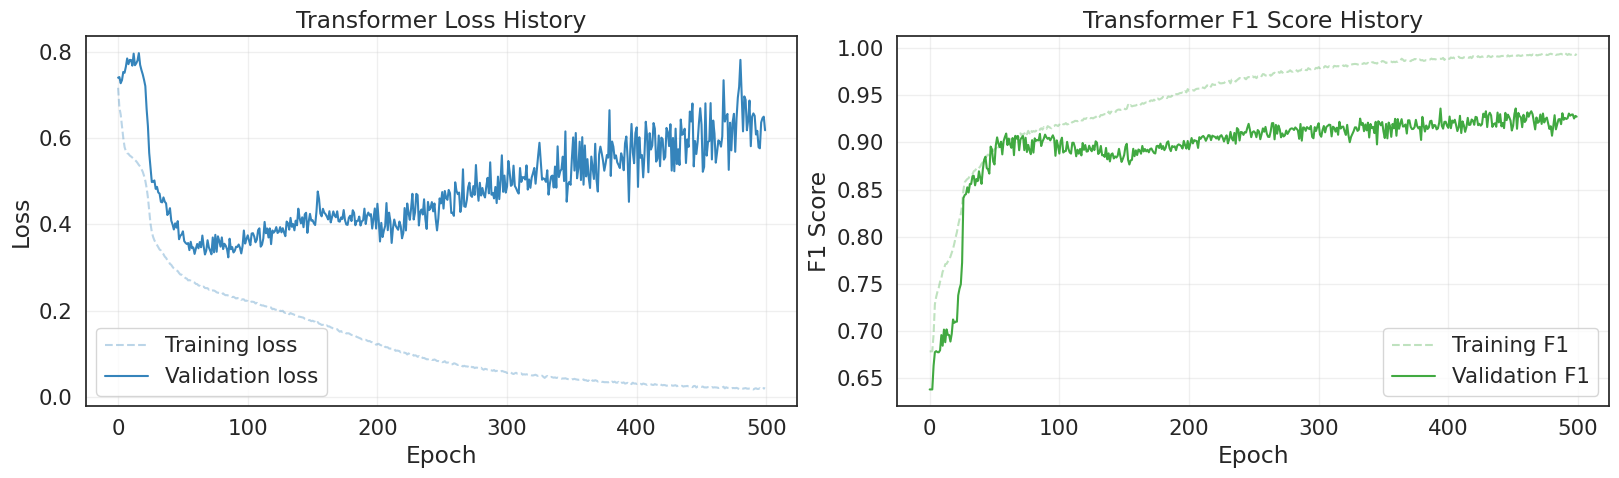

In [62]:
# @title Plot History
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history_transformer['train_loss'], label='Training loss', alpha=0.3, color='#1f77b4', linestyle='--')
ax1.plot(training_history_transformer['val_loss'], label='Validation loss', alpha=0.9, color='#1f77b4')
ax1.set_title('Transformer Loss History')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation F1 score on the second axis
ax2.plot(training_history_transformer['train_f1'], label='Training F1', alpha=0.3, color='#2ca02c', linestyle='--')
ax2.plot(training_history_transformer['val_f1'], label='Validation F1', alpha=0.9, color='#2ca02c')
ax2.set_title('Transformer F1 Score History')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.9)
plt.show()

##**TESTING**

In [64]:
from collections import Counter
from math import floor

def test_transformer_with_selected_subsequences(
    model,
    X_test_df,
    normalization_mins,
    normalization_maxs,
    window_size,
    stride,
    selected_indices_for_voting,
    preferential_index_for_tie_breaking,
    scale_columns
):
    model.eval() # Set model to evaluation mode

    # Ensure mapping dicts are accessible or recreated
    label_mapping_legs = {
        'two': 0,
        'one+peg_leg': 1,
    }
    label_mapping_hands = {
        'two': 0,
        'one+hook_hand': 1,
    }
    label_mapping_eyes = {
        'two': 0,
        'one+eye_patch': 1,
    }

    # Preprocess X_test_df (re-apply steps similar to training prep if not already done)
    # It's crucial that X_test_df passed to this function is the raw, untransformed one
    # or that the preprocessing steps below are idempotent.
    X_test_processed = X_test_df.copy()

    # Drop 'joint_30' if it exists
    if 'joint_30' in X_test_processed.columns:
        X_test_processed = X_test_processed.drop('joint_30', axis=1)

    # Convert joint columns to float32
    for i in range(30):
        col_name = f'joint_{i:02d}'
        if col_name in X_test_processed.columns:
            X_test_processed[col_name] = X_test_processed[col_name].astype(np.float32)

    # Map object columns to integers
    X_test_processed['n_legs'] = X_test_processed['n_legs'].map(label_mapping_legs)
    X_test_processed['n_hands'] = X_test_processed['n_hands'].map(label_mapping_hands)
    X_test_processed['n_eyes'] = X_test_processed['n_eyes'].map(label_mapping_eyes)

    # Apply normalization using training mins/maxs
    for column in scale_columns:
        X_test_processed[column] = (X_test_processed[column] - normalization_mins[column]) / \
                                   (normalization_maxs[column] - normalization_mins[column])

    # Define all columns to be used for building sequences - this must match the features used for training
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]

    # Generate all subsequences from the processed X_test_df
    # build_sequences_test is assumed to be globally available
    X_test_all_windowed = build_sequences_test(X_test_processed, window=window_size, stride=stride)
    X_test_all_windowed = np.array(X_test_all_windowed)

    # Create DataLoader for all subsequences
    all_sequences_ds = TensorDataset(torch.from_numpy(X_test_all_windowed))
    all_sequences_loader = make_loader(
        all_sequences_ds,
        batch_size=BATCH_SIZE_TRANSFORMER, # Using Transformer's batch size
        shuffle=False,
        drop_last=False
    )

    all_flat_predictions = []
    with torch.no_grad():
        for inputs in all_sequences_loader:
            inputs = inputs[0].to(device)
            outputs = model(inputs)
            _, predicted_classes = torch.max(outputs, 1)
            all_flat_predictions.extend(predicted_classes.cpu().numpy().tolist())

    all_flat_predictions = np.array(all_flat_predictions)

    # Get unique sample indices from the test set (original, not processed)
    unique_test_users = X_test_df['sample_index'].unique()
    original_sample_len = 160 # Length of each original sample

    # Calculate total subsequences generated per original sample
    padding_len_per_sample = window_size - (original_sample_len % window_size)
    if padding_len_per_sample == window_size:
        padding_len_per_sample = 0
    padded_len_per_sample = original_sample_len + padding_len_per_sample
    total_subsequences_per_original_sample = int(floor((padded_len_per_sample - window_size) / stride) + 1)

    final_predictions = []
    for i, sample_id in enumerate(unique_test_users):
        sample_predictions_start_idx = i * total_subsequences_per_original_sample
        sample_predictions_end_idx = sample_predictions_start_idx + total_subsequences_per_original_sample
        current_sample_all_predictions = all_flat_predictions[sample_predictions_start_idx:sample_predictions_end_idx]

        # Collect votes from selected subsequences
        votes = []
        for idx in selected_indices_for_voting:
            if idx < len(current_sample_all_predictions):
                votes.append(current_sample_all_predictions[idx])
            else:
                # Fallback if an index is out of bounds (shouldn't happen with correct calculation)
                votes.append(current_sample_all_predictions[0]) # Use first available if out of bounds

        vote_counts = Counter(votes)
        max_votes = 0
        if vote_counts:
            max_votes = max(vote_counts.values())
        majority_classes = [cls for cls, count in vote_counts.items() if count == max_votes]

        if len(majority_classes) == 1:
            final_predictions.append(majority_classes[0])
        else:
            # Tie-breaking: use the preferential subsequence's prediction
            if preferential_index_for_tie_breaking < len(current_sample_all_predictions):
                final_predictions.append(current_sample_all_predictions[preferential_index_for_tie_breaking])
            else:
                # Fallback if preferential index is also out of bounds
                final_predictions.append(majority_classes[0] if majority_classes else 0) # Default to 0 if no valid vote

    # Map numerical predictions to pain levels
    pain_level_mapping = {
        0: "no_pain",
        1: "low_pain",
        2: "high_pain"
    }
    pain_levels = [pain_level_mapping[pred] for pred in final_predictions]

    submission_df = pd.DataFrame({
        'sample_index': unique_test_users,
        'label': pain_levels
    })

    return submission_df

# Calculate selected subsequence indices for voting and tie-breaking
# Original sequence length is 160
# Window size = WINDOW_SIZE_TRANSFORMER (30)
# Stride = STRIDE_TRANSFORMER (5)

# A window from (1-indexed 51, 80) corresponds to (0-indexed 50, 79). Its index k = 50 // 5 = 10.
# A window from (1-indexed 61, 90) corresponds to (0-indexed 60, 89). Its index k = 60 // 5 = 12.
# A window from (1-indexed 71, 100) corresponds to (0-indexed 70, 99). Its index k = 70 // 5 = 14.
# A window from (1-indexed 81, 110) corresponds to (0-indexed 80, 109). Its index k = 80 // 5 = 16.

selected_subsequence_indices = [10, 11, 12, 13]
preferential_subsequence_index = 12 # Corresponding to (61, 90) 1-indexed

# Call the function to generate the submission DataFrame
submission_transformer_df = test_transformer_with_selected_subsequences(
    model=transformer_model,
    X_test_df=pd.read_csv('pirate_pain_test.csv'), # Pass the raw X_test for internal preprocessing
    normalization_mins=mins,
    normalization_maxs=maxs,
    window_size=WINDOW_SIZE_TRANSFORMER,
    stride=STRIDE_TRANSFORMER,
    selected_indices_for_voting=selected_subsequence_indices,
    preferential_index_for_tie_breaking=preferential_subsequence_index,
    scale_columns=scale_columns
)

# Define the submission filename
submission_filename_transformer = 'transformer_1.0.csv'

# Save the resulting submission DataFrame to the specified CSV file
submission_transformer_df.to_csv(submission_filename_transformer, index=False)

# Print a confirmation message and display the head of the generated DataFrame
print(f"Submission file '{submission_filename_transformer}' created successfully.")
display(submission_transformer_df.head())

Submission file 'transformer_1.0.csv' created successfully.


,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,no_pain
3,3,no_pain
4,4,no_pain
